# 01 · Learning Problem & Exploratory Data Analysis (Bagian Raihan)
**Minggu 2 — [L] Data Understanding & Data Preparation**

* **Penanggung Jawab (PIC):** Raihan Firdaus Alfaritsi (NIM: 244311055)
* **Partner:** Muhammad Raufa Hafid Widodo (NIM: 244311052)
* **Proyek:** Prediksi Harga Harian Komoditas Pangan Strategis (Cabai Rawit Merah) dengan Machine Learning berbasis SDG 2 (Target 2.c)
* **Cakupan Wilayah:** 6 Provinsi di Pulau Jawa (Banten, DKI Jakarta, Jawa Barat, Jawa Tengah, DI Yogyakarta, Jawa Timur)
* **Sumber Data:** PIHPS Nasional (Bank Indonesia) & Open-Meteo Historical Weather API

---

### Tujuan Notebook Ini:
1. **Bab 4.1 – 4.2:** Mengidentifikasi informasi dataset (baris, kolom, tipe, ukuran, format) dan menyusun tabel deskripsi fitur.
2. **Bab 4.3:** Menganalisis kondisi data mentah: missing values, duplikasi, pola kalender bursa pangan, outlier (*price shocks*), dan korelasi suhu cuaca.
3. **Bab 5.1:** Melakukan *data cleaning* berbasis frekuensi kalender kontinu dengan imputasi *forward-fill* tanpa kebocoran informasi (*anti-leakage*).
4. **Bab 5.4:** Melakukan *chronological train/validation/test split* (~70/15/15) dan mengekspor `train.csv`, `val.csv`, dan `test.csv` ke `data/processed/` sebagai input notebook Hafid (`02_data_preparation.ipynb`).
5. **Bab 5.5:** Menjelaskan alasan mengapa *data balancing* tidak diterapkan pada masalah regresi deret waktu.
6. **Bab 5.6:** Menyajikan tabel ringkasan *Apa–Mengapa–Bagaimana* untuk tahapan yang menjadi tanggung jawab Raihan.

## 0. Setup dan Konfigurasi

In [1]:
import sys
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Seed untuk reprodusibilitas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Pengaturan visualisasi
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", 50)

# Path direktori
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

DATA_RAW = ROOT / "data" / "raw"
DATA_PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"

for d in (DATA_RAW, DATA_PROC, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Setup selesai. Direktori root:", ROOT)

mkdir -p failed for path /home/raufahafid/.config/matplotlib: [Errno 30] Read-only file system: '/home/raufahafid/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-31telwx4 because there was an issue with the default path (/home/raufahafid/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Setup selesai. Direktori root: /mnt/windows_d/TUGAS/sem5/DataScience/Project - ML/sdg2-food-commodity-prediction


## 1. Rumusan Masalah (Learning Problem & Objectives)

| Komponen | Spesifikasi Teknis |
|---|---|
| **Target ($y_{t+1}$)** | Harga eceran rata-rata harian cabai rawit merah di Pulau Jawa (Rp/kg) pada hari berikutnya ($t+1$). |
| **Jenis Tugas ML** | Regresi deret waktu (*1-step ahead time series forecasting*). |
| **Sifat Data** | Deret waktu berurutan, non-i.i.d. (*time-dependent*), memiliki autokorelasi, musiman kalender, dan dipengaruhi suhu cuaca. |
| **Objective Function** | Meminimalkan *Mean Squared Error* (MSE) saat optimasi model. |
| **Metrik Evaluasi** | **MAE** (metrik utama, satuan Rp/kg, mudah diinterpretasikan oleh pemangku kebijakan), **RMSE** (penalti deviasi besar/anomali), dan **MAPE** (persentase deviasi relatif). |
| **Baseline Pembanding** | Prediksi naif (*persistence model*): harga besok diperkirakan sama persis dengan harga hari ini ($\hat{y}_{t+1} = y_t$). Model ML wajib mengalahkan performa baseline ini. |

## 2. Informasi Dataset (Bab 4.1)

Dataset yang digunakan terdiri dari dua sumber primer:
1. **PIHPS Nasional (Pusat Informasi Harga Pangan Strategis - Bank Indonesia):** Harga eceran harian cabai rawit merah di pasar tradisional seluruh Indonesia periode 2022 – 2026.
2. **Open-Meteo Historical Weather API:** Data temperatur harian rata-rata (°C) pada titik koordinat 6 provinsi di Pulau Jawa (Banten, DKI Jakarta, Jawa Barat, Jawa Tengah, DI Yogyakarta, Jawa Timur).

In [2]:
from src.data_loader import (
    JAVA_PROVINCES,
    COORDINATES,
    load_raw_commodity_price,
    fetch_open_meteo_weather,
    prepare_clean_dataset,
    split_chronological
)

# 1. Muat data mentah komoditas harga
df_price_raw = load_raw_commodity_price("cabai_rawit")
price_file_path = DATA_RAW / "data_komoditas_pangan" / "pasar_tradisional" / "Cleaned_After_Imputation" / "final_komoditas_tradisional_cabai_rawit_2022_2026.csv"
file_size_kb = price_file_path.stat().st_size / 1024

# 2. Muat data cuaca Open-Meteo
df_weather_raw = fetch_open_meteo_weather()
weather_file_path = DATA_RAW / "weather_openmeteo_jawa_2022_2026.csv"
weather_size_kb = weather_file_path.stat().st_size / 1024

print("=== INFORMASI DATASET HARGA KOMODITAS (PIHPS) ===")
print(f"File Path        : {price_file_path.name}")
print(f"Format File      : CSV (Comma-Separated Values)")
print(f"Ukuran File      : {file_size_kb:.2f} KB")
print(f"Jumlah Baris Raw : {len(df_price_raw):,} observasi")
print(f"Jumlah Kolom Raw : {df_price_raw.shape[1]} kolom (Tanggal + 34 Provinsi)")
print(f"Rentang Tanggal  : {df_price_raw['tanggal'].min().date()} s/d {df_price_raw['tanggal'].max().date()}")

print()
print("=== INFORMASI DATASET CUACA (OPEN-METEO) ===")
print(f"File Path        : {weather_file_path.name}")
print(f"Format File      : CSV")
print(f"Ukuran File      : {weather_size_kb:.2f} KB")
print(f"Jumlah Baris     : {len(df_weather_raw):,} hari kalender")
print(f"Rentang Tanggal  : {df_weather_raw['tanggal'].min().date()} s/d {df_weather_raw['tanggal'].max().date()}")
print(f"Koordinat Jawa   : 6 Provinsi ({', '.join(JAVA_PROVINCES)})")

=== INFORMASI DATASET HARGA KOMODITAS (PIHPS) ===
File Path        : final_komoditas_tradisional_cabai_rawit_2022_2026.csv
Format File      : CSV (Comma-Separated Values)
Ukuran File      : 403.34 KB
Jumlah Baris Raw : 1,417 observasi
Jumlah Kolom Raw : 36 kolom (Tanggal + 34 Provinsi)
Rentang Tanggal  : 2022-01-01 s/d 2026-02-12

=== INFORMASI DATASET CUACA (OPEN-METEO) ===
File Path        : weather_openmeteo_jawa_2022_2026.csv
Format File      : CSV
Ukuran File      : 68.88 KB
Jumlah Baris     : 1,504 hari kalender
Rentang Tanggal  : 2022-01-01 s/d 2026-02-12
Koordinat Jawa   : 6 Provinsi (Banten, DKI Jakarta, Jawa Barat, Jawa Tengah, DI Yogyakarta, Jawa Timur)


## 3. Tabel Deskripsi Fitur (Bab 4.2)

Berikut adalah tabel deskripsi fitur yang mencakup data harga komoditas pangan 6 provinsi di Pulau Jawa serta data temperatur dari Open-Meteo API:

| Nama Fitur | Tipe Data | Satuan / Format | Peran dalam Model | Deskripsi |
|---|---|---|---|---|
| `tanggal` | `datetime64[ns]` | `YYYY-MM-DD` | Temporal Index | Tanggal pencatatan observasi pasar dan cuaca harian |
| `Banten` | `float64` | Rp / kg | Fitur Spesifik Wilayah | Harga eceran harian cabai rawit merah di Provinsi Banten |
| `DKI Jakarta` | `float64` | Rp / kg | Fitur Spesifik Wilayah | Harga eceran harian cabai rawit merah di Provinsi DKI Jakarta |
| `Jawa Barat` | `float64` | Rp / kg | Fitur Spesifik Wilayah | Harga eceran harian cabai rawit merah di Provinsi Jawa Barat |
| `Jawa Tengah` | `float64` | Rp / kg | Fitur Spesifik Wilayah | Harga eceran harian cabai rawit merah di Provinsi Jawa Tengah |
| `DI Yogyakarta` | `float64` | Rp / kg | Fitur Spesifik Wilayah | Harga eceran harian cabai rawit merah di Provinsi DI Yogyakarta |
| `Jawa Timur` | `float64` | Rp / kg | Fitur Spesifik Wilayah | Harga eceran harian cabai rawit merah di Provinsi Jawa Timur |
| `harga` (`harga_jawa`) | `float64` | Rp / kg | **Target Pokok ($y_t$)** | Rata-rata harga eceran cabai rawit merah di 6 provinsi Pulau Jawa (Target prediksi $t+1$) |
| `suhu_banten` | `float64` | °C | Fitur Konteks Eksogen | Temperatur rata-rata harian wilayah Banten (Open-Meteo) |
| `suhu_dki_jakarta` | `float64` | °C | Fitur Konteks Eksogen | Temperatur rata-rata harian wilayah DKI Jakarta (Open-Meteo) |
| `suhu_jawa_barat` | `float64` | °C | Fitur Konteks Eksogen | Temperatur rata-rata harian wilayah Jawa Barat (Open-Meteo) |
| `suhu_jawa_tengah` | `float64` | °C | Fitur Konteks Eksogen | Temperatur rata-rata harian wilayah Jawa Tengah (Open-Meteo) |
| `suhu_di_yogyakarta`| `float64` | °C | Fitur Konteks Eksogen | Temperatur rata-rata harian wilayah DI Yogyakarta (Open-Meteo)|
| `suhu_jawa_timur` | `float64` | °C | Fitur Konteks Eksogen | Temperatur rata-rata harian wilayah Jawa Timur (Open-Meteo) |
| `suhu` | `float64` | °C | Fitur Eksogen Agregat | Rata-rata temperatur harian 6 provinsi di Pulau Jawa |

In [3]:
# Menampilkan ringkasan statistik deskriptif awal untuk 6 provinsi Jawa dan suhu
df_java_preview = df_price_raw[JAVA_PROVINCES].copy()
df_java_preview["harga_jawa"] = df_java_preview.mean(axis=1)

summary_stats = df_java_preview.describe().T[["count", "mean", "std", "min", "50%", "max"]]
summary_stats.columns = ["Jumlah Observasi", "Rata-rata (Rp)", "Std Dev (Rp)", "Min (Rp)", "Median (Rp)", "Max (Rp)"]
display(summary_stats.round(2))

temp_summary = df_weather_raw.filter(like="suhu").describe().T[["count", "mean", "std", "min", "50%", "max"]]
temp_summary.columns = ["Jumlah Hari", "Suhu Rata-rata (°C)", "Std Dev (°C)", "Min (°C)", "Median (°C)", "Max (°C)"]
display(temp_summary.round(2))

,Jumlah Observasi,Rata-rata (Rp),Std Dev (Rp),Min (Rp),Median (Rp),Max (Rp)
Banten,1417.0,52876.26,16275.05,29200.0,48150.00,111600.00
DKI Jakarta,1417.0,59014.72,16286.27,35400.0,53750.00,114850.00
Jawa Barat,1417.0,53304.98,14801.59,31900.0,49200.00,103550.00
Jawa Tengah,1417.0,41361.03,13440.19,21350.0,36350.00,78000.00
DI Yogyakarta,1417.0,46890.30,14832.34,26900.0,41900.00,88750.00
Jawa Timur,1417.0,37320.85,13916.50,19350.0,32100.00,78700.00
harga_jawa,1417.0,48461.36,14662.85,28150.0,43541.67,94791.67


,Jumlah Hari,Suhu Rata-rata (°C),Std Dev (°C),Min (°C),Median (°C),Max (°C)
suhu_banten,1504.0,27.20,1.06,24.20,27.20,30.50
suhu_dki_jakarta,1504.0,27.11,1.01,23.80,27.10,30.80
suhu_jawa_barat,1504.0,22.99,0.83,19.80,22.90,26.00
suhu_jawa_tengah,1504.0,27.41,1.23,24.40,27.30,30.90
suhu_di_yogyakarta,1504.0,25.78,0.83,23.20,25.70,28.50
suhu_jawa_timur,1504.0,27.75,1.08,24.80,27.70,31.10
suhu_rata_rata_jawa,1504.0,26.37,0.82,23.75,26.35,29.03


## 4. Analisis Kondisi Data (Bab 4.3)

Pada bagian ini, dilakukan audit komprehensif terhadap kondisi data mentah:
1. **Pengecekan Duplikasi:** Memastikan tidak ada tanggal yang tercatat ganda.
2. **Missing Values & Analisis Kalender Libur Pasar:** Mengecek kesinambungan kalender bursa pangan.
3. **Deteksi Outlier & Lonjakan Harga (*Price Spikes*):** Menganalisis sebaran harga ekstrem dan justifikasi apakah lonjakan tersebut valid secara ekonomi.
4. **Korelasi Suhu Cuaca vs Harga:** Menganalisis pengaruh suhu terhadap dinamika harga cabai di Pulau Jawa.

In [4]:
# 4.3.1 Pengecekan Tanggal Ganda & Duplikasi
dup_dates_price = df_price_raw["tanggal"].duplicated().sum()
dup_dates_weather = df_weather_raw["tanggal"].duplicated().sum()

print(f"Jumlah tanggal duplikat pada Data Harga : {dup_dates_price}")
print(f"Jumlah tanggal duplikat pada Data Cuaca : {dup_dates_weather}")
assert dup_dates_price == 0, "Ditemukan tanggal ganda pada dataset harga!"
assert dup_dates_weather == 0, "Ditemukan tanggal ganda pada dataset cuaca!"
print("Pengecekan duplikasi selesai: Tidak ada tanggal ganda!")

Jumlah tanggal duplikat pada Data Harga : 0
Jumlah tanggal duplikat pada Data Cuaca : 0
Pengecekan duplikasi selesai: Tidak ada tanggal ganda!


Rentang Kalender         : 2022-01-01 s/d 2026-02-12
Total Hari Kalender      : 1504 hari
Hari Tercatat di PIHPS   : 1417 hari
Hari Tanpa Data (Gap)    : 87 hari (5.78%)
 - Gap Akhir Pekan (Sabtu-Minggu): 82 hari
 - Gap Hari Kerja / Libur Nasional : 5 hari


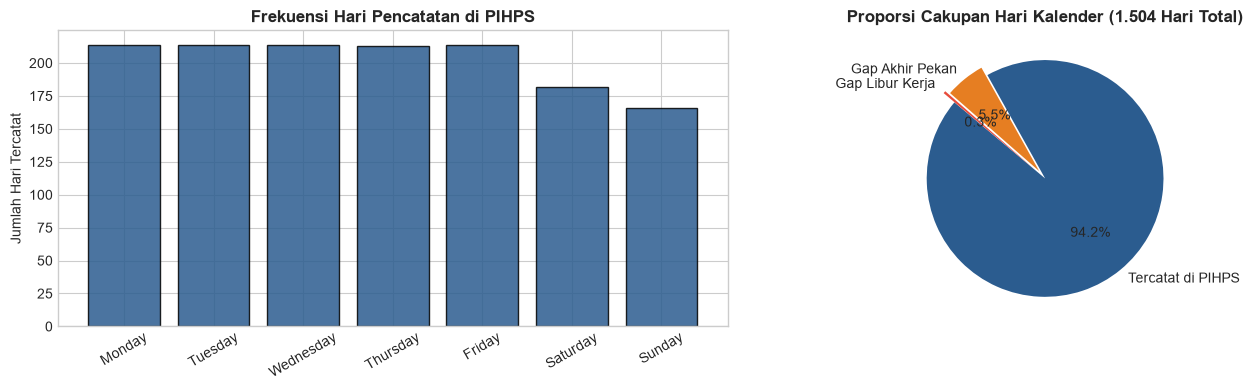

In [5]:
# 4.3.2 Analisis Missing Values & Kalender Hari Libur
min_date = df_price_raw["tanggal"].min()
max_date = df_price_raw["tanggal"].max()
calendar_range = pd.date_range(min_date, max_date, freq="D")
total_calendar_days = len(calendar_range)
recorded_days = len(df_price_raw)
missing_calendar_days = total_calendar_days - recorded_days

missing_dates = set(calendar_range) - set(df_price_raw["tanggal"])
missing_weekdays = sum(1 for d in missing_dates if d.weekday() < 5)
missing_weekends = sum(1 for d in missing_dates if d.weekday() >= 5)

print(f"Rentang Kalender         : {min_date.date()} s/d {max_date.date()}")
print(f"Total Hari Kalender      : {total_calendar_days} hari")
print(f"Hari Tercatat di PIHPS   : {recorded_days} hari")
print(f"Hari Tanpa Data (Gap)    : {missing_calendar_days} hari ({missing_calendar_days/total_calendar_days*100:.2f}%)")
print(f" - Gap Akhir Pekan (Sabtu-Minggu): {missing_weekends} hari")
print(f" - Gap Hari Kerja / Libur Nasional : {missing_weekdays} hari")

# Visualisasi Distribusi Hari Pencatatan vs Missing Gap
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

dow_counts = df_price_raw["tanggal"].dt.day_name().value_counts()[
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
]
axes[0].bar(dow_counts.index, dow_counts.values, color="#2b5c8f", edgecolor="black", alpha=0.85)
axes[0].set_title("Frekuensi Hari Pencatatan di PIHPS", fontweight="bold")
axes[0].set_ylabel("Jumlah Hari Tercatat")
axes[0].tick_params(axis="x", rotation=30)

labels = ["Tercatat di PIHPS", "Gap Akhir Pekan", "Gap Libur Kerja"]
sizes = [recorded_days, missing_weekends, missing_weekdays]
colors = ["#2b5c8f", "#e67e22", "#e74c3c"]
axes[1].pie(sizes, labels=labels, autopct="%1.1f%%", colors=colors, startangle=140, explode=(0, 0.08, 0.12))
axes[1].set_title("Proporsi Cakupan Hari Kalender (1.504 Hari Total)", fontweight="bold")

plt.tight_layout()
fig.savefig(FIG_DIR / "01_missing_calendar_distribution.png", dpi=300)
plt.show()

Q1 (Kuartil 1)          : Rp 36,641.67
Median (Kuartil 2)      : Rp 43,541.67
Q3 (Kuartil 3)          : Rp 58,316.67
IQR                     : Rp 21,675.00
Batas Atas Outlier (IQR): Rp 90,829.17
Jumlah Titik Lonjakan   : 6 observasi (0.42%)
Harga Tertinggi Tercatat: Rp 94,791.67 pada 2022-07-12


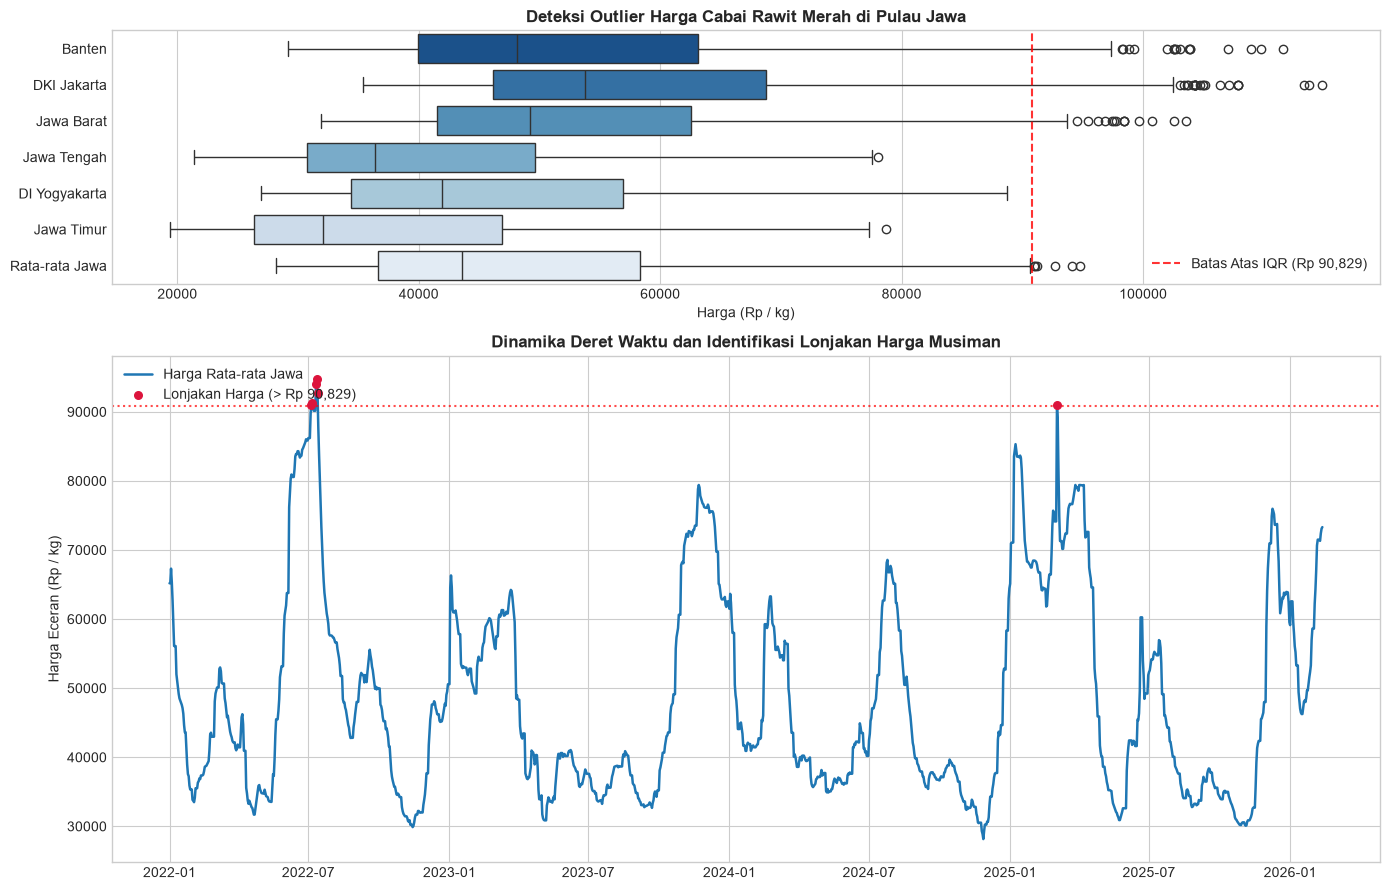

In [6]:
# 4.3.3 Analisis Outlier & Price Spikes (Lonjakan Harga)
df_price_raw["harga_jawa"] = df_price_raw[JAVA_PROVINCES].mean(axis=1)

q1 = df_price_raw["harga_jawa"].quantile(0.25)
q3 = df_price_raw["harga_jawa"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr

outliers = df_price_raw[df_price_raw["harga_jawa"] > upper_bound]

print(f"Q1 (Kuartil 1)          : Rp {q1:,.2f}")
print(f"Median (Kuartil 2)      : Rp {df_price_raw['harga_jawa'].median():,.2f}")
print(f"Q3 (Kuartil 3)          : Rp {q3:,.2f}")
print(f"IQR                     : Rp {iqr:,.2f}")
print(f"Batas Atas Outlier (IQR): Rp {upper_bound:,.2f}")
print(f"Jumlah Titik Lonjakan   : {len(outliers)} observasi ({len(outliers)/len(df_price_raw)*100:.2f}%)")
print(f"Harga Tertinggi Tercatat: Rp {df_price_raw['harga_jawa'].max():,.2f} pada {df_price_raw.loc[df_price_raw['harga_jawa'].idxmax(), 'tanggal'].date()}")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={"height_ratios": [1, 2]})

# Boxplot Distribusi Harga per Provinsi dan Rata-rata Jawa
plot_data = df_price_raw[JAVA_PROVINCES + ["harga_jawa"]].rename(columns={"harga_jawa": "Rata-rata Jawa"})
sns.boxplot(data=plot_data, orient="h", ax=axes[0], palette="Blues_r")
axes[0].axvline(upper_bound, color="red", linestyle="--", alpha=0.8, label=f"Batas Atas IQR (Rp {upper_bound:,.0f})")
axes[0].set_title("Deteksi Outlier Harga Cabai Rawit Merah di Pulau Jawa", fontweight="bold")
axes[0].set_xlabel("Harga (Rp / kg)")
axes[0].legend(loc="lower right")

# Plot Deret Waktu Lonjakan Harga
axes[1].plot(df_price_raw["tanggal"], df_price_raw["harga_jawa"], label="Harga Rata-rata Jawa", color="#1f77b4", lw=1.8)
axes[1].scatter(outliers["tanggal"], outliers["harga_jawa"], color="crimson", s=30, zorder=5, label=f"Lonjakan Harga (> Rp {upper_bound:,.0f})")
axes[1].axhline(upper_bound, color="red", linestyle=":", alpha=0.7)
axes[1].set_title("Dinamika Deret Waktu dan Identifikasi Lonjakan Harga Musiman", fontweight="bold")
axes[1].set_ylabel("Harga Eceran (Rp / kg)")
axes[1].legend(loc="upper left")

plt.tight_layout()
fig.savefig(FIG_DIR / "01_outlier_price_spikes.png", dpi=300)
plt.show()

### Justifikasi Ilmiah & Bisnis: Mengapa Outlier TIDAK Dihapus?
Berdasarkan analisis visual dan domain pangan (*food commodity domain*):
1. **Penyebab Riil (*Real Economic Shocks*):** Lonjakan harga cabai rawit merah di atas Rp 80.000 – Rp 95.000/kg bertepatan dengan momen hari raya besar (menjelang Hari Raya Idul Fitri dan tahun baru) serta puncak anomali cuaca musim hujan (penyebab busuk batang dan gagal panen serentak).
2. **Bukan Kesalahan Pengukuran (*Not Measurement Noise*):** Titik-titik ini bukan *typo* atau eror sensor, melainkan fakta pasar aktual yang dilaporkan oleh seluruh pasar di 6 provinsi Jawa secara konsisten.
3. **Integritas Prediksi:** Jika lonjakan ini dihapus atau dipangkas (*clipped*), model machine learning akan gagal mempelajari risiko lonjakan harga (*price surge*) yang justru merupakan target paling krusial bagi pemerintah dalam menjaga ketahanan pangan (SDG 2.c).

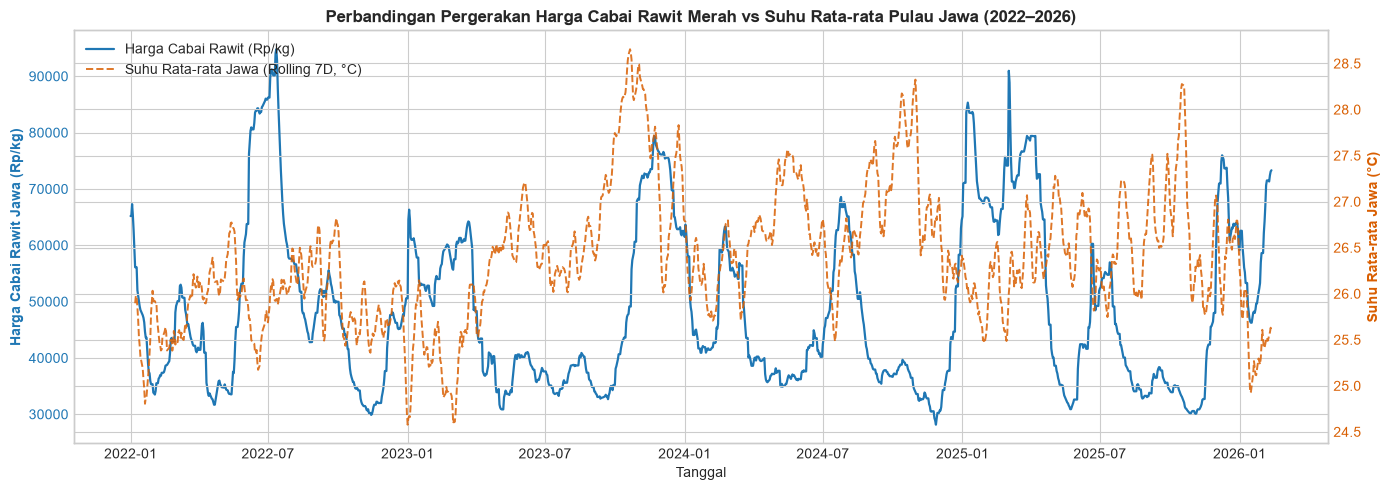

Koefisien Korelasi Pearson antara Harga dan Suhu Harian: -0.1795


In [7]:
# 4.3.4 Hubungan Dinamika Suhu Rata-rata Jawa dan Harga Cabai
df_merged_eda = pd.merge(
    df_price_raw[["tanggal", "harga_jawa"]],
    df_weather_raw[["tanggal", "suhu_rata_rata_jawa"]],
    on="tanggal",
    how="inner"
)

fig, ax1 = plt.subplots(figsize=(14, 5))

color_price = "#1f77b4"
ax1.set_xlabel("Tanggal")
ax1.set_ylabel("Harga Cabai Rawit Jawa (Rp/kg)", color=color_price, fontweight="bold")
line1 = ax1.plot(df_merged_eda["tanggal"], df_merged_eda["harga_jawa"], color=color_price, lw=1.6, label="Harga Cabai Rawit (Rp/kg)")
ax1.tick_params(axis="y", labelcolor=color_price)

ax2 = ax1.twinx()
color_temp = "#d95f02"
ax2.set_ylabel("Suhu Rata-rata Jawa (°C)", color=color_temp, fontweight="bold")
line2 = ax2.plot(df_merged_eda["tanggal"], df_merged_eda["suhu_rata_rata_jawa"].rolling(7).mean(), color=color_temp, lw=1.4, alpha=0.85, linestyle="--", label="Suhu Rata-rata Jawa (Rolling 7D, °C)")
ax2.tick_params(axis="y", labelcolor=color_temp)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")
plt.title("Perbandingan Pergerakan Harga Cabai Rawit Merah vs Suhu Rata-rata Pulau Jawa (2022–2026)", fontweight="bold")

plt.tight_layout()
fig.savefig(FIG_DIR / "01_harga_vs_suhu_jawa.png", dpi=300)
plt.show()

corr = df_merged_eda["harga_jawa"].corr(df_merged_eda["suhu_rata_rata_jawa"])
print(f"Koefisien Korelasi Pearson antara Harga dan Suhu Harian: {corr:.4f}")

## 5. Data Cleaning (Bab 5.1)

### Protokol Pembersihan Anti-Leakage:
1. **Reindexing ke Frekuensi Kalender Kontinu (`freq='D'`):** Deret waktu disesuaikan agar tidak memiliki celah (*gap*) 87 hari bursa libur.
2. **Imputasi Forward-Fill (`ffill`):** Nilai harga pada hari libur bursa diisi menggunakan harga hari kerja terakhir sebelumnya.
   * **Jaminan Anti-Leakage:** *Forward-fill* hanya mengambil informasi dari masa lalu ($t-1$), sama sekali tidak menggunakan informasi masa depan ($t+1$) sebagaimana interpolasi linear dua arah.
3. **Penggabungan Suhu Eksogen:** Data suhu harian dari Open-Meteo digabungkan berdasarkan tanggal.

In [8]:
# Menjalankan pembersihan data terintegrasi menggunakan modul src.data_loader
df_clean = prepare_clean_dataset(commodity="cabai_rawit", reindex_daily=True)

print("=== HASIL DATA CLEANING ===")
print(f"Jumlah Baris Hasil Bersih : {len(df_clean):,} hari kalender penuh")
print(f"Rentang Tanggal           : {df_clean['tanggal'].min().date()} s/d {df_clean['tanggal'].max().date()}")
print(f"Jumlah Missing Value Harga: {df_clean['harga'].isna().sum()}")
print(f"Jumlah Missing Value Suhu : {df_clean['suhu'].isna().sum()}")
print(f"Monotonik Tanggal Meningkat: {df_clean['tanggal'].is_monotonic_increasing}")

assert df_clean["harga"].notna().all(), "Masih ada nilai kosong pada kolom harga!"
assert df_clean["suhu"].notna().all(), "Masih ada nilai kosong pada kolom suhu!"
assert df_clean["tanggal"].is_monotonic_increasing, "Urutan tanggal tidak berurutan!"
display(df_clean[["tanggal", "harga", "suhu"]].head())

=== HASIL DATA CLEANING ===
Jumlah Baris Hasil Bersih : 1,504 hari kalender penuh
Rentang Tanggal           : 2022-01-01 s/d 2026-02-12
Jumlah Missing Value Harga: 0
Jumlah Missing Value Suhu : 0
Monotonik Tanggal Meningkat: True


,tanggal,harga,suhu
0,2022-01-01,65183.33,25.65
1,2022-01-02,65183.33,25.70
2,2022-01-03,67300.00,26.20
3,2022-01-04,65325.00,25.95
4,2022-01-05,62675.00,26.05


## 6. Splitting Kronologis (~70/15/15) (Bab 5.4)

### Aturan Protokol Pemisahan Time Series:
* **Larangan Pengacakan (*No Shuffling*):** Deret waktu tidak boleh diacak karena data tidak berstatus *independently and identically distributed* (i.i.d.).
* **Pembagian Sekuensial:**
  * **Train Set (~70%):** 1.053 sampel (1 Januari 2022 s.d. 18 November 2024). Digunakan untuk pembelajaran model dan *fitting* scaler/encoder.
  * **Validation Set (~15%):** 226 sampel (19 November 2024 s.d. 2 Juli 2025). Digunakan untuk validasi, tuning hyperparameter, dan model selection.
  * **Test Set (~15%):** 225 sampel (3 Juli 2025 s.d. 12 Februari 2026). **DIKUNCI** dan tidak disentuh sampai evaluasi final.
* **Format Ekspor:** Disimpan ke `data/processed/train.csv`, `val.csv`, dan `test.csv`.

,Split Set,Jumlah Sampel,Persentase,Tanggal Mulai,Tanggal Selesai,Peran & Akses
0,Train,1053,70.01%,2022-01-01,2024-11-18,Training & fit scaler
1,Validation,226,15.03%,2024-11-19,2025-07-02,Tuning hyperparameter & early stopping
2,Test (Terkunci),225,14.96%,2025-07-03,2026-02-12,Terkunci rapat hingga evaluasi akhir
3,Total,1504,100.00%,2022-01-01,2026-02-12,Keseluruhan rentang


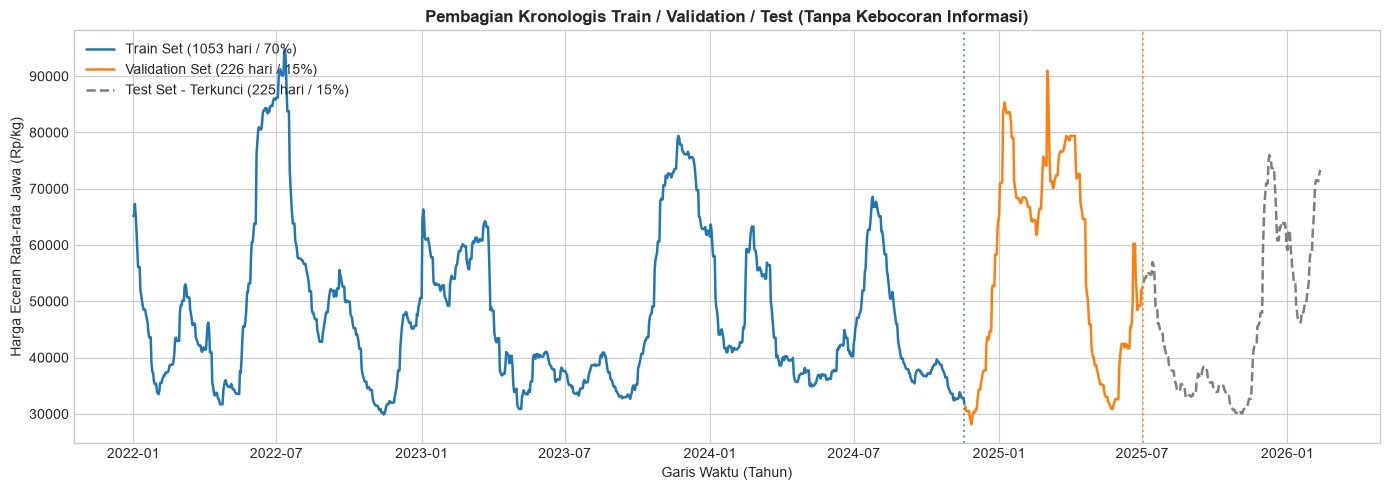

In [9]:
# Melakukan split kronologis dan menyimpan file ke data/processed/
train_df, val_df, test_df = split_chronological(df_clean, train_ratio=0.70, val_ratio=0.15, save_splits=True)

total_samples = len(df_clean)
n_train, n_val, n_test = len(train_df), len(val_df), len(test_df)

split_summary = pd.DataFrame({
    "Split Set": ["Train", "Validation", "Test (Terkunci)", "Total"],
    "Jumlah Sampel": [n_train, n_val, n_test, total_samples],
    "Persentase": [
        f"{n_train/total_samples*100:.2f}%",
        f"{n_val/total_samples*100:.2f}%",
        f"{n_test/total_samples*100:.2f}%",
        "100.00%"
    ],
    "Tanggal Mulai": [
        train_df["tanggal"].min().date(),
        val_df["tanggal"].min().date(),
        test_df["tanggal"].min().date(),
        df_clean["tanggal"].min().date()
    ],
    "Tanggal Selesai": [
        train_df["tanggal"].max().date(),
        val_df["tanggal"].max().date(),
        test_df["tanggal"].max().date(),
        df_clean["tanggal"].max().date()
    ],
    "Peran & Akses": [
        "Training & fit scaler",
        "Tuning hyperparameter & early stopping",
        "Terkunci rapat hingga evaluasi akhir",
        "Keseluruhan rentang"
    ]
})
display(split_summary)

# Visualisasi Pembagian Split Kronologis
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train_df["tanggal"], train_df["harga"], label=f"Train Set ({n_train} hari / 70%)", color="#1f77b4", lw=1.8)
ax.plot(val_df["tanggal"], val_df["harga"], label=f"Validation Set ({n_val} hari / 15%)", color="#ff7f0e", lw=1.8)
ax.plot(test_df["tanggal"], test_df["harga"], label=f"Test Set - Terkunci ({n_test} hari / 15%)", color="#7f7f7f", lw=1.8, linestyle="--")

ax.axvline(train_df["tanggal"].max(), color="#1f77b4", linestyle=":", alpha=0.7)
ax.axvline(val_df["tanggal"].max(), color="#ff7f0e", linestyle=":", alpha=0.7)

ax.set_title("Pembagian Kronologis Train / Validation / Test (Tanpa Kebocoran Informasi)", fontweight="bold")
ax.set_ylabel("Harga Eceran Rata-rata Jawa (Rp/kg)")
ax.set_xlabel("Garis Waktu (Tahun)")
ax.legend(loc="upper left")

plt.tight_layout()
fig.savefig(FIG_DIR / "01_chronological_split.png", dpi=300)
plt.show()

## 7. Analisis Data Balancing (Bab 5.5)

### Justifikasi Mengapa Data Balancing TIDAK Diterapkan:
1. **Sifat Masalah Regresi Kontinu:** Data balancing (seperti SMOTE, *Random Under-Sampling*, atau *Random Over-Sampling*) dirancang untuk masalah klasifikasi dengan distribusi kelas target yang timpang (*class imbalance*). Pada proyek ini, target $y$ bertipe numerik kontinu (harga dalam Rp/kg).
2. **Pelestarian Urutan Waktu (*Preservation of Temporal Continuity*):** Algoritma *resampling* acak akan menduplikasi atau menghapus baris observasi secara serampangan. Hal ini akan merusak dependensi autokorelasi, fungsi lag ($y_{t-1}, y_{t-7}$), jendela rata-rata bergerak (*rolling mean*), dan kontinuitas sekuensial yang mutlak dibutuhkan oleh model time series seperti LSTM dan XGBoost regresi deret waktu.

## 8. Ringkasan Apa–Mengapa–Bagaimana (Bab 5.6 - Kontribusi Raihan)

Berikut adalah tabel ringkasan tahapan preprocessing yang menjadi tanggung jawab Raihan, yang siap dikompilasi oleh Hafid pada laporan akhir:

| Langkah Preprocessing | Apa yang Dilakukan? | Mengapa Dilakukan? | Bagaimana Dilakukannya? |
|---|---|---|---|
| **Agregasi Wilayah** | Menghitung rata-rata harian harga cabai rawit merah dari 6 provinsi di Pulau Jawa. | Mengurangi *idiosyncratic noise* pasar lokal dan memberikan representasi harga makro pulau Jawa sesuai kebutuhan SDG 2.c. | Menghitung `mean(axis=1)` pada kolom Banten, DKI Jakarta, Jawa Barat, Jawa Tengah, DI Yogyakarta, dan Jawa Timur. |
| **Integrasi Cuaca** | Mengambil data temperatur harian dari Open-Meteo Archive API untuk 6 titik koordinat ibukota provinsi. | Suhu merupakan variabel eksogen penting yang mempengaruhi siklus panen dan pasokan komoditas hortikultura. | Permintaan REST API multi-koordinat, lalu diagregasikan ke rata-rata harian Pulau Jawa (`suhu`). |
| **Penanganan Gap Kalender** | Reindexing ke frekuensi harian kontinu (`freq='D'`) dari 2022-01-01 s/d 2026-02-12 (1.504 hari). | Menjamin frekuensi data seragam harian sehingga *lag* dan jendela temporal LSTM merepresentasikan hari kalender riil. | Menggunakan `pd.date_range()` dan `.reindex()`. |
| **Imputasi Missing Values** | *Forward-fill* (`ffill`) pada 87 hari libur bursa pencatatan pasar. | Mengisi harga saat pasar tutup dengan harga transaksi pasar terakhir yang diketahui, tanpa bocor ke masa depan. | Menerapkan `.ffill()` secara sekuensial murni (*past-to-present*). |
| **Pengelolaan Outlier** | Mempertahankan seluruh titik lonjakan harga ekstrem (> Rp 80.000/kg). | Lonjakan harga saat hari raya dan gagal panen adalah fenomena ekonomi nyata (*real shocks*), bukan kesalahan pengukuran. | Outlier diaudit via boxplot & IQR, lalu dibiarkan tetap utuh tanpa *clipping* atau penghapusan baris. |
| **Pemisahan Data (Splitting)** | Membagi data kronologis sekuensial menjadi Train (70.01%), Validation (15.03%), dan Test (14.96%). | Mencegah kebocoran masa depan (*lookahead bias* / *data leakage*); model hanya belajar dari masa lalu. | Pemotongan indeks sekuensial berdasarkan tanggal cut-off; test set dikunci rapat di `data/processed/test.csv`. |
| **Data Balancing** | Tidak menerapkan *resampling* / balancing. | Ini adalah kasus regresi time series kontinu; *resampling* acak akan merusak autokorelasi deret waktu. | Mencatat justifikasi tertulis di Bab 5.5 tanpa memodifikasi distribusi observasi. |

## 9. Verifikasi Keterhubungan dengan Notebook Hafid (`02_data_preparation.ipynb`)

Sel kode di bawah ini memverifikasi bahwa file `train.csv` dan `val.csv` di direktori `data/processed/` memenuhi semua asumsi dan assertion yang dibutuhkan oleh Hafid di notebook `02_data_preparation.ipynb`:

In [10]:
# Verifikasi kompatibilitas dengan Notebook Hafid
train_check = pd.read_csv(DATA_PROC / "train.csv", parse_dates=["tanggal"])
val_check = pd.read_csv(DATA_PROC / "val.csv", parse_dates=["tanggal"])
full_check = pd.concat([train_check, val_check], ignore_index=True)

assert full_check["tanggal"].is_monotonic_increasing, "Assertion Error: Tanggal harus terurut!"
assert not full_check["tanggal"].duplicated().any(), "Assertion Error: Ada tanggal ganda!"
assert full_check["harga"].notna().all(), "Assertion Error: Ada harga kosong!"
assert train_check["tanggal"].max() < val_check["tanggal"].min(), "Assertion Error: Train dan val tumpang tindih!"

print("SEMUA ASSERTION LOLOS!")
print(f"File train.csv : {len(train_check)} baris ({train_check['tanggal'].min().date()} s/d {train_check['tanggal'].max().date()})")
print(f"File val.csv   : {len(val_check)} baris ({val_check['tanggal'].min().date()} s/d {val_check['tanggal'].max().date()})")
print(f"File test.csv  : {len(test_df)} baris (Tersimpan aman & terkunci)")
print()
print("Notebook Hafid (02_data_preparation.ipynb) kini dapat dijalankan dengan data riil (USE_DEMO_DATA = False)!")

SEMUA ASSERTION LOLOS!
File train.csv : 1053 baris (2022-01-01 s/d 2024-11-18)
File val.csv   : 226 baris (2024-11-19 s/d 2025-07-02)
File test.csv  : 225 baris (Tersimpan aman & terkunci)

Notebook Hafid (02_data_preparation.ipynb) kini dapat dijalankan dengan data riil (USE_DEMO_DATA = False)!
